In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

In [2]:
# Load dataset
df = pd.read_csv('logatta.csv')

In [3]:
# Show the first 5 rows
df.head()

,Age,BusinessTravel,Education,MaritalStatus,OverTime,EmployeeNumber,DailyRate,Gender,accepted for the interview
0,41,Travel_Rarely,2,Single,Yes,1,1102,Female,True
1,49,Travel_Frequently,1,Married,No,2,279,Male,False
2,37,Travel_Rarely,2,Single,Yes,4,1373,Male,False
3,33,Travel_Frequently,4,Married,Yes,5,1392,Female,False
4,27,Travel_Rarely,1,Married,No,7,591,Male,False


In [4]:
# View data types and non-null counts
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1492 entries, 0 to 1491
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Age                         1492 non-null   int64 
 1   BusinessTravel              1492 non-null   object
 2   Education                   1492 non-null   int64 
 3   MaritalStatus               1492 non-null   object
 4   OverTime                    1492 non-null   object
 5   EmployeeNumber              1492 non-null   int64 
 6   DailyRate                   1492 non-null   int64 
 7   Gender                      1492 non-null   object
 8   accepted for the interview  1492 non-null   bool  
dtypes: bool(1), int64(4), object(4)
memory usage: 94.8+ KB


In [5]:
# Statistical details of columns
df.describe()

,Age,Education,EmployeeNumber,DailyRate
count,1492.000000,1492.000000,1492.000000,1492.000000
mean,36.885389,2.916220,1036.963137,804.987936
std,9.102789,1.021738,605.700269,403.804253
min,18.000000,1.000000,1.000000,0.000000
25%,30.000000,2.000000,496.750000,466.750000
50%,36.000000,3.000000,1034.500000,804.500000
75%,43.000000,4.000000,1581.250000,1162.000000
max,60.000000,5.000000,2068.000000,1499.000000


In [6]:
# Check for any missing values (NaN)
df.isnull().sum()

Age                           0
BusinessTravel                0
Education                     0
MaritalStatus                 0
OverTime                      0
EmployeeNumber                0
DailyRate                     0
Gender                        0
accepted for the interview    0
dtype: int64

In [7]:
# Convert categorical (text) columns into numeric using pandas get_dummies
df = pd.get_dummies(df, drop_first=True)

In [8]:
# Define target column (accepted for the interview) and features
target_column = 'accepted for the interview'
X = df.drop(columns=[target_column])
y = df[target_column].astype(int) # Convert True/False to 1/0

In [9]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [10]:
# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
# Initialize models
models = {
    "Logistic Regression": LogisticRegression(class_weight='balanced', random_state=42),
    "Naive Bayes": GaussianNB(),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}


Logistic Regression -> Accuracy: 0.9666


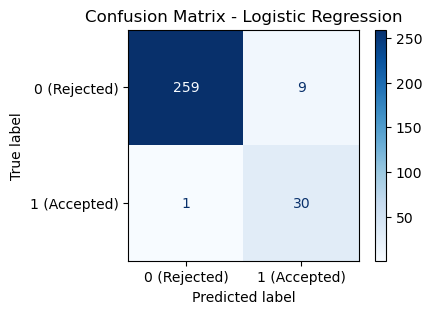


Naive Bayes -> Accuracy: 0.9565


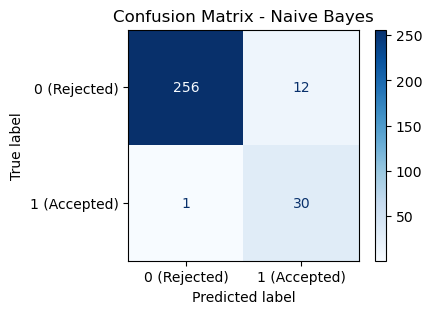


KNN -> Accuracy: 0.9666


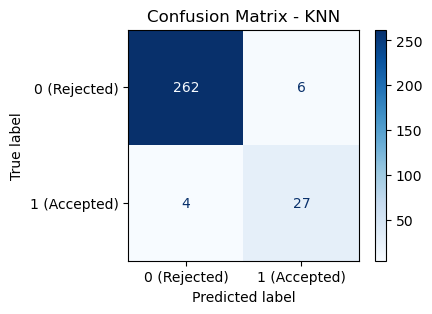

In [12]:
# Train, evaluate, and plot confusion matrix for each model
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    
    print(f"\n{name} -> Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    
    # Confusion Matrix Visualization
    fig, ax = plt.subplots(figsize=(4, 3))
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['0 (Rejected)', '1 (Accepted)'])
    disp.plot(ax=ax, cmap='Blues', values_format='d')
    plt.title(f'Confusion Matrix - {name}')
    plt.show()

In [13]:
# Test predictions on individual samples
sample_rejected = df[df[target_column] == False].iloc[0:1].drop(columns=[target_column])
sample_accepted = df[df[target_column] == True].iloc[0:1].drop(columns=[target_column])

print("Rejected sample prediction (Expected 0):", models["Logistic Regression"].predict(scaler.transform(sample_rejected))[0])
print("Accepted sample prediction (Expected 1):", models["Logistic Regression"].predict(scaler.transform(sample_accepted))[0])

Rejected sample prediction (Expected 0): 0
Accepted sample prediction (Expected 1): 1
